# Garmin_R1_SegmentBased_Review
R1 whole-run label: build the rules and review the results. Labels a random sample of runs and plots a few per label class.

**Inputs**
- `.fit` files in `garmin_data\DI_CONNECT\Sorted\Run`, runs on or after `MIN_DATE` for review purposes

**Logic**
1. Pick a random pool of runs (`POOL_SIZE`)
2. Label each run: load, clean speed, resample to 1 Hz, split into segments, label segments relative to the run's median speed, merge fast segments into fast stretches, apply rules to give the whole-run label, check the last quarter for strides
3. Pick `N_PER_CLASS` runs from each label class
4. Plot each pick: HR and pace on top, segment types below, R1 label in the title

**Outputs**
- Label counts for the pool and the list of runs picked for review
- One plot per picked run, shown in the notebook

## R1 rules

**Segment types** (relative to the run's median speed)

| Segment type | Rule |
|---|---|
| Strides | Under 45 s and faster than 1.40x |
| Recovery | Slower than 0.80x |
| Fast/Effort | Faster than 1.08x |
| Z2/Easy | Everything else |

**Fast stretch:** one continuous period of faster running. Fast/Effort segments that touch are merged into one fast stretch. Any other segment type between them ends the stretch. A fast stretch counts only if it lasts at least 45 s.

**Run labels** (checked in order, first match wins)

| Order | Run label | Rule |
|---|---|---|
| 1 | Z2/Steady State with Strides | 2 or more fast stretches, all starting in the last quarter of the run, longest 5 min or less |
| 2 | Structured Intervals | 3 or more fast stretches |
| 3 | Tempo Run | 1 fast stretch of 8 min or more |
| 3 | Tempo Run | 2 fast stretches, each 5 min or more, with a gap of 2 min or less (split tempo) |
| 4 | Structured Intervals | Exactly 2 fast stretches that are not a split tempo |
| 5 | Z2/Steady State | Everything else |

**Strides added after the order above**
- A Z2/Steady State run becomes Z2/Steady State with Strides if the last quarter has 3 or more efforts of 8 to 75 s at 1.20x median speed or faster.
- A run containing a Strides segment gets "with Strides" added to its label.

## 1. Setup and configuration

In [1]:
import random
from datetime import datetime
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from garmin_fit_sdk import Decoder, Stream

# Paths
RUN_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\DI_CONNECT\Sorted\Run")  #Should be altered to where the sorted run directory is.

# Sample
POOL_SIZE = 80  #Number of runs picked at random from RUN_DIR and labelled, so each label has enough runs to pick from for the plots
N_PER_CLASS = 2  #Maximum number of runs plotted for each label
RANDOM_SEED = 42  #Seed set so the same runs are picked each time
MIN_DATE = datetime(2024, 10, 4)  #Only runs on or after this date can be picked

# Loading and cleaning
MIN_RECORDS = 50  #Files with fewer than 50 usable records (HR, speed and timestamp all present) are skipped
MAX_SPEED_KMH = 25  #Speed readings above this are treated as glitches and set to NaN
MAX_INTERP_GAP_S = 5  #Longest run of blank speed readings (in seconds) filled with a straight line; after the first 5 in a longer gap, the nearest good value is used

# Segmentation
ROLLING_WINDOW = 30  #Window (in seconds) used to measure how much speed is changing
VARIANCE_THRESHOLD_PCTL = 85  #Speed change above this percentile of the run is treated as a pace change
MIN_SEGMENT_LENGTH = 60  #Segments shorter than this (in seconds) are merged into the next one

# Segment types (multiples of run median speed)
STRIDE_SEG_MAX_S = 45  #A Strides segment is shorter than this (in seconds)
STRIDE_SEG_SPEED_MULT = 1.40  #A Strides segment is faster than this
RECOVERY_SPEED_MULT = 0.80  #A Recovery segment is slower than this
FAST_SPEED_MULT = 1.08  #A Fast/Effort segment is faster than this

# Whole-run rules
MIN_BOUT_S = 45  #A fast stretch must last at least this long (in seconds) to count
TEMPO_MIN_S = 8 * 60  #A single fast stretch this long or longer makes a Tempo Run
SPLIT_TEMPO_MIN_BOUT_S = 5 * 60  #Split tempo: each of the two fast stretches must be at least this long
SPLIT_TEMPO_MAX_GAP_S = 2 * 60  #Split tempo: the gap between the two fast stretches must be no longer than this
TAIL_PATTERN_MAX_BOUT_S = 5 * 60  #Strides pattern: the longest fast stretch must be no longer than this
TAIL_FRACTION = 0.25  #The "tail" of a run is its final quarter

# Tail strides - settings to allow detection of strides at the end of the run
TAIL_STRIDE_SPEED_MULT = 1.20  #A stride must be at least this multiple of median speed
TAIL_STRIDE_MIN_S = 8  #Shortest a stride can be (in seconds)
TAIL_STRIDE_MAX_S = 75  #Longest a stride can be (in seconds)
TAIL_STRIDE_MIN_COUNT = 3  #Strides are only counted if at least this many are found

## 2. Load, clean and resample

In [2]:
def extract_run(fpath):
    stream = Stream.from_file(str(fpath))
    decoder = Decoder(stream)
    messages, errors = decoder.read()

    if "session_mesgs" not in messages or "record_mesgs" not in messages:
        return None

    rows = []
    for record in messages["record_mesgs"]:
        hr = record.get("heart_rate")
        speed = record.get("enhanced_speed", record.get("speed"))
        timestamp = record.get("timestamp")
        if None not in (hr, speed, timestamp):
            rows.append({"timestamp": timestamp, "heart_rate": hr, "speed": speed})

    if len(rows) < MIN_RECORDS:
        return None

    df = pd.DataFrame(rows).sort_values("timestamp").reset_index(drop=True)
    df["elapsed_s"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds()
    return df

#Clean speed , convert from m/s to km/h - remove implausible and interpolate
def clean_speed(speed_array, max_kmh=MAX_SPEED_KMH):
    speed_kmh = speed_array * 3.6 #converts m/s to km/h
    implausible = (speed_kmh > max_kmh) | (speed_kmh < 0) #flags any reading above 25 km/h (about 2:24 min/km pace)
    cleaned = pd.Series(speed_array.copy())
    cleaned[implausible] = np.nan
    cleaned = cleaned.interpolate(limit=MAX_INTERP_GAP_S)  #draws straight line between results to interpolate
    return cleaned.bfill().ffill().to_numpy() #copies in nearest good value into any blanks left
 
#resamples HR and speed into a 1s grid so we can use a rolling window approach 
def resample_to_1s(df):
    df = df.drop(columns=["timestamp"])
    for col in ["heart_rate", "speed"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    indexed = df.set_index("elapsed_s")   #makes elapsed seconds the row labels
    full_index = np.arange(0, int(indexed.index.max()) + 1, 1)   #list of every whole second from 0 to the end of the run
    resampled = indexed.reindex(indexed.index.union(full_index)).sort_index()   #adds a blank row for each missing second and puts rows in time order
    resampled = resampled.interpolate(method="linear", limit_direction="both")  #fills blanks with a straight line between the readings either side
    resampled = resampled.reindex(full_index) #keeps only the whole-second rows
    resampled["elapsed_s"] = resampled.index #puts elapsed seconds back as a normal column
    return resampled.reset_index(drop=True)


def prepare_run(fpath):
    df = extract_run(fpath)
    if df is None:
        return None
    df["speed"] = clean_speed(df["speed"].to_numpy())
    return resample_to_1s(df)

## 3. Segmentation and segment types

In [3]:
def detect_segments(df, rolling_window=ROLLING_WINDOW, pctl=VARIANCE_THRESHOLD_PCTL, min_len=MIN_SEGMENT_LENGTH):
    speed = df["speed"].to_numpy()
    n = len(speed)
    rolling_var = pd.Series(speed).rolling(rolling_window, center=True, min_periods=1).var().fillna(0.0).to_numpy()
    threshold = np.percentile(rolling_var, pctl)
    is_transition = rolling_var > threshold

    boundaries = [0]
    current_state = is_transition[0]
    for index in range(1, n):
        if is_transition[index] != current_state:
            boundaries.append(index)
            current_state = is_transition[index]
    boundaries.append(n)

    segments = []
    segment_start = boundaries[0]
    for boundary in boundaries[1:]:
        if boundary - segment_start >= min_len:
            segments.append((segment_start, boundary))
            segment_start = boundary
    if segment_start < n:
        segments.append((segment_start, n))
    return segments


def classify_segment_type(seg_speed, seg_length_s, run_median_speed):
    avg_speed = seg_speed.mean()
    if seg_length_s < STRIDE_SEG_MAX_S and avg_speed > run_median_speed * STRIDE_SEG_SPEED_MULT:
        return "Strides"
    if avg_speed < run_median_speed * RECOVERY_SPEED_MULT:
        return "Recovery"
    if avg_speed > run_median_speed * FAST_SPEED_MULT:
        return "Fast/Effort"
    return "Z2/Easy"


def get_fast_bouts(run_segments):
    fast_bouts = []
    current = None
    for _, segment in run_segments.sort_values("start_s").iterrows():
        if segment["type_label"] != "Fast/Effort":
            current = None
            continue
        if current is not None and segment["start_s"] <= current["end_s"] + 1:
            old_duration = current["duration_s"]
            added_duration = segment["length_s"]
            total_duration = old_duration + added_duration
            current["avg_speed"] = (current["avg_speed"] * old_duration + segment["avg_speed"] * added_duration) / total_duration
            current["end_s"] = segment["end_s"]
            current["duration_s"] = total_duration
        else:
            current = {"start_s": segment["start_s"], "end_s": segment["end_s"],
                       "duration_s": segment["length_s"], "avg_speed": segment["avg_speed"]}
            fast_bouts.append(current)
    return fast_bouts

## 4. Whole-run label

In [4]:
#Finds strides in the last quarter of the run: 3 or more efforts of 8-75 s at 1.20x median speed or faster
def detect_tail_strides(df, run_median_speed, tail_fraction=TAIL_FRACTION,
                        speed_multiplier=TAIL_STRIDE_SPEED_MULT,
                        min_stride_s=TAIL_STRIDE_MIN_S, 
                        max_stride_s=TAIL_STRIDE_MAX_S,
                        min_stride_count=TAIL_STRIDE_MIN_COUNT):
    speed = df["speed"].to_numpy()
    elapsed = df["elapsed_s"].to_numpy()
    tail_start_s = elapsed[-1] * (1 - tail_fraction)
    tail_indices = np.where(elapsed >= tail_start_s)[0]
    if len(tail_indices) == 0:
        return []
    smooth_speed = pd.Series(speed).rolling(5, center=True, min_periods=1).median().to_numpy()
    stride_threshold = run_median_speed * speed_multiplier
    above_threshold = smooth_speed >= stride_threshold
    above_threshold[:tail_indices[0]] = False

    strides = []
    index = tail_indices[0]
    while index < len(above_threshold):
        if not above_threshold[index]:
            index += 1
            continue
        start_idx = index
        while index < len(above_threshold) and above_threshold[index]:
            index += 1
        end_idx = index
        duration_s = end_idx - start_idx
        if min_stride_s <= duration_s <= max_stride_s:
            strides.append({"start_idx": start_idx, "end_idx": end_idx, "start_s": elapsed[start_idx],
                            "end_s": elapsed[end_idx - 1], "duration_s": duration_s,
                            "avg_speed": np.nanmean(speed[start_idx:end_idx])})
        index += 1
    return strides if len(strides) >= min_stride_count else []

#Gives the whole-run label from the fast stretches, applying the rules in order (first match wins)
def summarize_run_type(run_segments):
    fast_bouts = get_fast_bouts(run_segments)
    meaningful = [b for b in fast_bouts if b["duration_s"] >= MIN_BOUT_S]
    durations = [b["duration_s"] for b in meaningful]
    run_median_speed = run_segments["run_median_speed"].iloc[0]
    clear_interval_bouts = [b for b in meaningful if b["avg_speed"] >= run_median_speed * FAST_SPEED_MULT]
    interval_count = len(clear_interval_bouts)

    run_end_s = run_segments["end_s"].max()
    final_quarter_start = run_end_s * (1 - TAIL_FRACTION)
    tail_stride_pattern = (
        len(meaningful) >= 2
        and all(b["start_s"] >= final_quarter_start for b in meaningful)
        and max(durations) <= TAIL_PATTERN_MAX_BOUT_S
    )

    if tail_stride_pattern:
        base = "Z2/Steady State with Strides"
    elif interval_count >= 3:
        base = "Structured Intervals"
    elif len(meaningful) == 1:
        base = "Tempo Run" if meaningful[0]["duration_s"] >= TEMPO_MIN_S else "Z2/Steady State"
    elif len(meaningful) == 2:
        recovery_duration = meaningful[1]["start_s"] - meaningful[0]["end_s"]
        split_tempo = (min(meaningful[0]["duration_s"], meaningful[1]["duration_s"]) >= SPLIT_TEMPO_MIN_BOUT_S
                       and recovery_duration <= SPLIT_TEMPO_MAX_GAP_S)
        if split_tempo:
            base = "Tempo Run"
        elif interval_count == 2:
            base = "Structured Intervals"
        else:
            base = "Z2/Steady State"
    else:
        base = "Z2/Steady State"

    if (run_segments["type_label"] == "Strides").any() and "with Strides" not in base:
        base += " with Strides"
    return base

#Runs the full R1 process on one run: segments, whole-run label and strides. Returns None if no segments are found
def label_run(df):
    speed = df["speed"].to_numpy()
    moving_speed = speed[speed > 0]
    run_median_speed = np.median(moving_speed) if len(moving_speed) else speed.mean()

    segments = detect_segments(df)
    if len(segments) == 0:
        return None

    rows = []
    for start, end in segments:
        seg_speed = speed[start:end]
        seg_length_s = end - start
        rows.append({
            "start_s": start, "end_s": end, "length_s": seg_length_s,
            "avg_speed": seg_speed.mean(), "run_median_speed": run_median_speed,
            "type_label": classify_segment_type(seg_speed, seg_length_s, run_median_speed),
        })
    run_segments = pd.DataFrame(rows)

    label = summarize_run_type(run_segments)
    strides = detect_tail_strides(df, run_median_speed)
    if label == "Z2/Steady State" and strides:
        label = "Z2/Steady State with Strides"

    return {"label": label, "segments": run_segments, "strides": strides}

## 5. Select a random sample of runs

In [5]:
def parse_date_from_filename(fpath):
    date_str = fpath.stem.split("__")[0]
    return datetime.strptime(date_str, "%d%m%Y")


run_files = list(RUN_DIR.glob("*.fit"))
print(f"Total sorted running files: {len(run_files)}")

file_dates = [(f, parse_date_from_filename(f)) for f in run_files]
file_dates = [(f, d) for f, d in file_dates if d >= MIN_DATE]
file_dates.sort(key=lambda x: x[1])

random.seed(RANDOM_SEED)
pool = sorted(random.sample(file_dates, min(POOL_SIZE, len(file_dates))), key=lambda x: x[1])
print(f"Sampled {len(pool)} runs from {len(file_dates)} on or after {MIN_DATE.date()}")

Total sorted running files: 1891
Sampled 80 runs from 375 on or after 2024-10-04


## 6. Label the sample

In [6]:
labelled = []
for fpath, date in pool:
    try:
        df = prepare_run(fpath)
        result = label_run(df) if df is not None else None
    except Exception as exc:
        print(f"Failed on {fpath.name}: {exc}")
        continue
    if result is None:
        continue
    labelled.append({"file": fpath.name, "date": date, "df": df, **result})

print(f"Labelled {len(labelled)} of {len(pool)} runs\n")
print(pd.Series([r["label"] for r in labelled]).value_counts())

Labelled 80 of 80 runs

Z2/Steady State                 46
Z2/Steady State with Strides    15
Tempo Run                       11
Structured Intervals             8
Name: count, dtype: int64


## 7. Pick runs to review from each label class

In [7]:
random.seed(RANDOM_SEED)
reviewed = []
for label in sorted({r["label"] for r in labelled}):
    group = [r for r in labelled if r["label"] == label]
    reviewed += random.sample(group, min(N_PER_CLASS, len(group)))
reviewed.sort(key=lambda r: (r["label"], r["date"]))

for run_idx, run in enumerate(reviewed):
    print(f"Run {run_idx} ({run['date'].date()}, {run['file']}): {run['label']}")

Run 0 (2025-04-18, 18042025__326749106193.fit): Structured Intervals
Run 1 (2025-05-06, 06052025__331380912674.fit): Structured Intervals
Run 2 (2025-07-05, 05072025__346817230622.fit): Tempo Run
Run 3 (2026-01-02, 02012026__395577015007.fit): Tempo Run
Run 4 (2025-02-24, 24022025__314103804640.fit): Z2/Steady State
Run 5 (2025-05-12, 12052025__332692767386.fit): Z2/Steady State
Run 6 (2024-10-28, 28102024__288092310069.fit): Z2/Steady State with Strides
Run 7 (2025-08-18, 18082025__358415942608.fit): Z2/Steady State with Strides


## 8. Plot function

In [8]:
TYPE_COLORS = {"Z2/Easy": "#e3f2fd", "Fast/Effort": "#ffccbc", "Recovery": "#c8e6c9", "Strides": "#d1c4e9"}


def format_time_axis(x, pos):
    total_minutes = x / 60
    if total_minutes < 60:
        return f"{total_minutes:.0f}m"
    hours = int(total_minutes // 60)
    mins = int(total_minutes % 60)
    return f"{hours}:{mins:02d}"


def format_pace(x, pos):
    if x <= 0 or np.isnan(x):
        return ""
    minutes = int(x)
    seconds = int(round((x - minutes) * 60))
    if seconds == 60:
        minutes += 1
        seconds = 0
    return f"{minutes}:{seconds:02d}"


def plot_run(run, run_idx):
    df = run["df"]
    elapsed = df["elapsed_s"].to_numpy()
    heart_rate = df["heart_rate"].to_numpy()
    speed = df["speed"].to_numpy()
    run_segments = run["segments"]
    strides = run["strides"]

    speed_safe = speed.copy()
    speed_safe[speed_safe < 0.3] = np.nan
    pace_min_per_km = 1000 / (60 * speed_safe)

    fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(13, 5), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})

    ax0.plot(elapsed, heart_rate, color="black", linewidth=1, alpha=0.5)
    ax0.set_ylabel("Heart rate (bpm)")
    duration_min = elapsed[-1] / 60
    ax0.set_title(f"Run {run_idx} - {run['date'].date()} ({run['file']}) - "
                  f"{duration_min:.0f} min - R1 LABEL: {run['label']}")
    ax0.xaxis.set_major_formatter(ticker.FuncFormatter(format_time_axis))

    ax0b = ax0.twinx()
    ax0b.plot(elapsed, pace_min_per_km, color="blue", linewidth=1, alpha=0.4)
    ax0b.set_ylabel("Pace (min/km)", color="blue")
    ax0b.invert_yaxis()
    valid_pace = pace_min_per_km[~np.isnan(pace_min_per_km)]
    if len(valid_pace) > 0:
        ax0b.set_ylim(bottom=min(np.percentile(valid_pace, 95), 15))
    ax0b.yaxis.set_major_formatter(ticker.FuncFormatter(format_pace))

    for _, seg in run_segments.iterrows():
        ax1.axvspan(seg["start_s"], seg["end_s"], color=TYPE_COLORS.get(seg["type_label"], "white"), alpha=0.7)

    for s in strides:
        ax0.axvspan(s["start_s"], s["end_s"], color="purple", alpha=0.3)

    ax1.set_yticks([])
    ax1.set_xlabel("Elapsed time")
    ax1.set_title(f"R1 segments  (purple bands on HR panel = {len(strides)} detected strides)")

    line_handles = [
        mlines.Line2D([], [], color="black", alpha=0.5, label="Raw HR"),
        mlines.Line2D([], [], color="blue", alpha=0.4, label="Pace"),
    ]
    ax0.legend(handles=line_handles, loc="upper left", bbox_to_anchor=(1.12, 1))
    type_handles = [mpatches.Patch(color=c, label=l, alpha=0.7) for l, c in TYPE_COLORS.items()]
    ax1.legend(handles=type_handles, loc="upper left", bbox_to_anchor=(1.12, 1))

    plt.tight_layout()
    plt.show()

## 9. Plot the reviewed runs

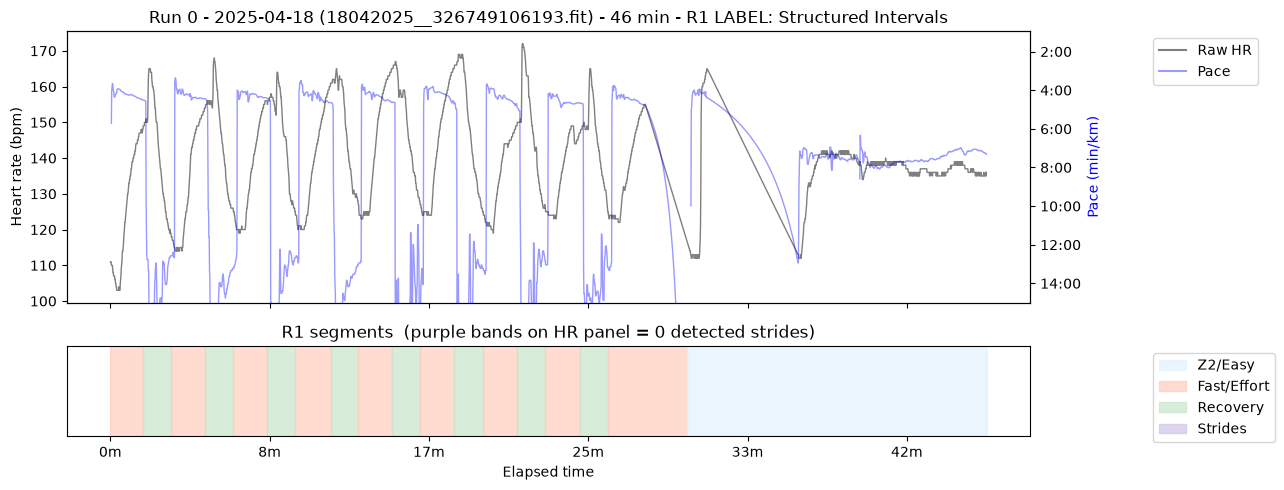

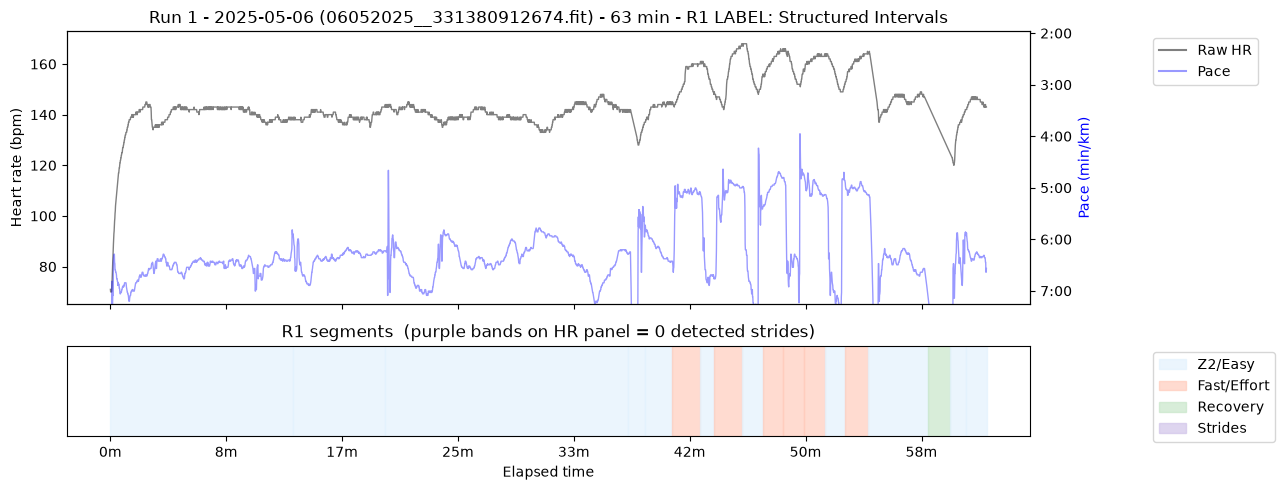

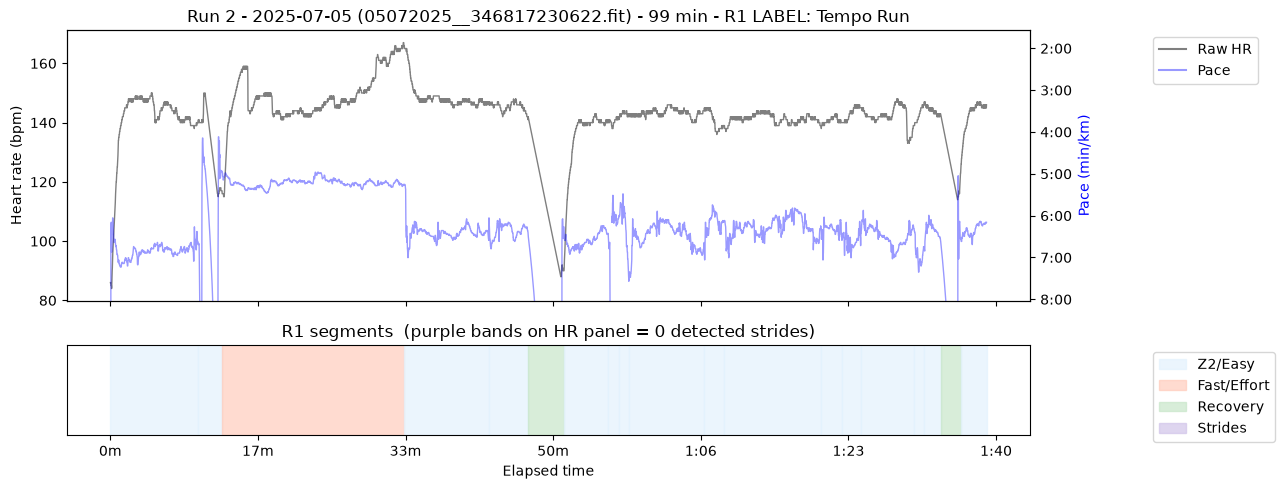

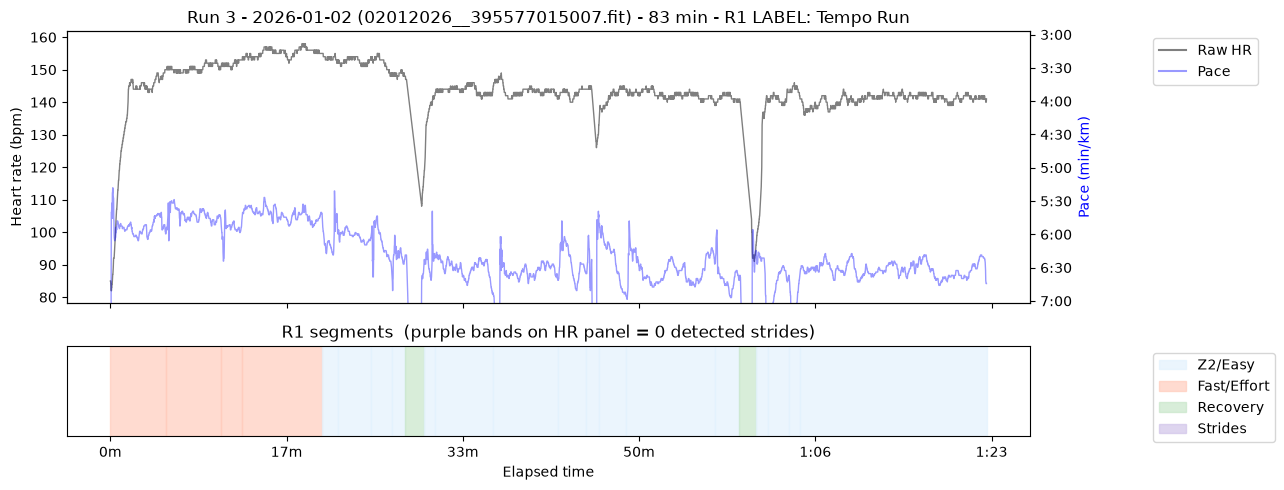

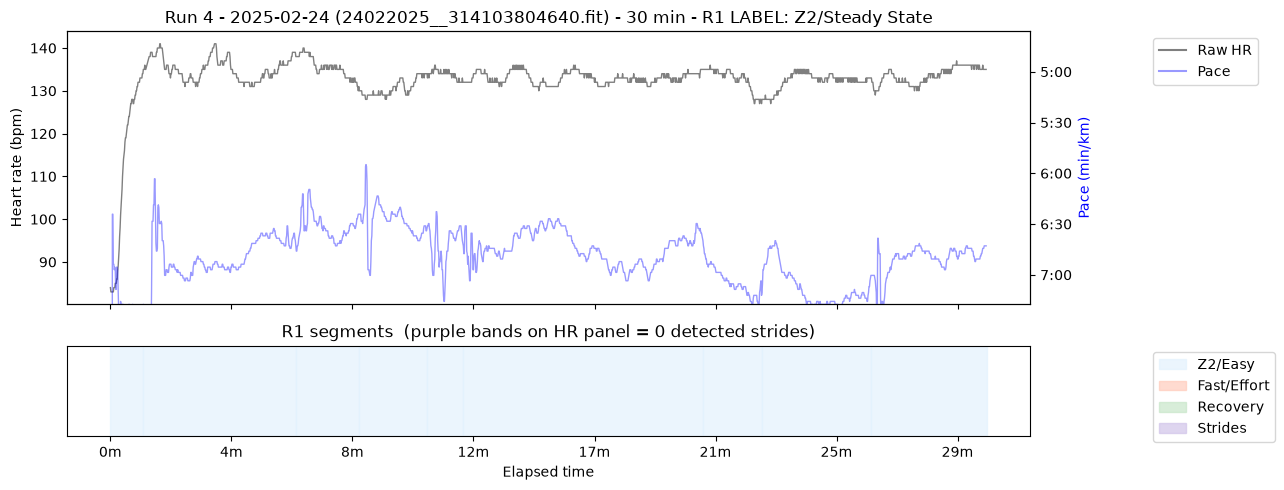

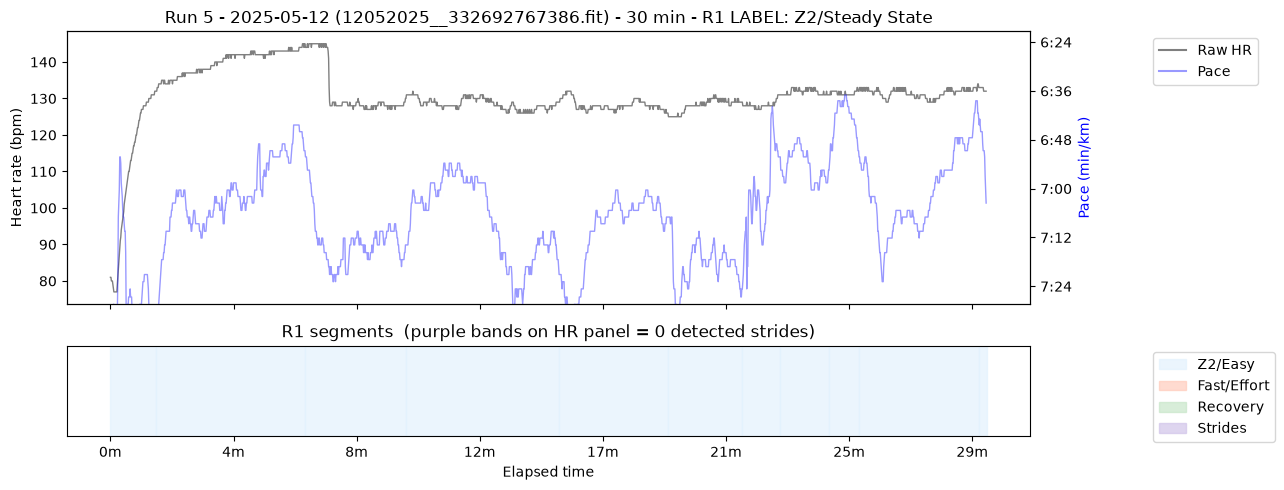

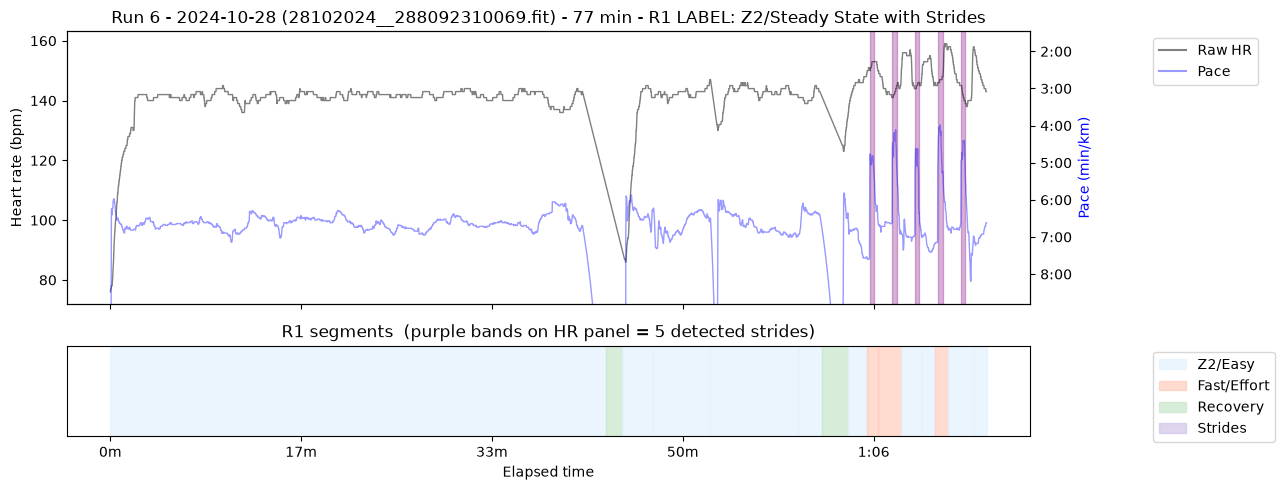

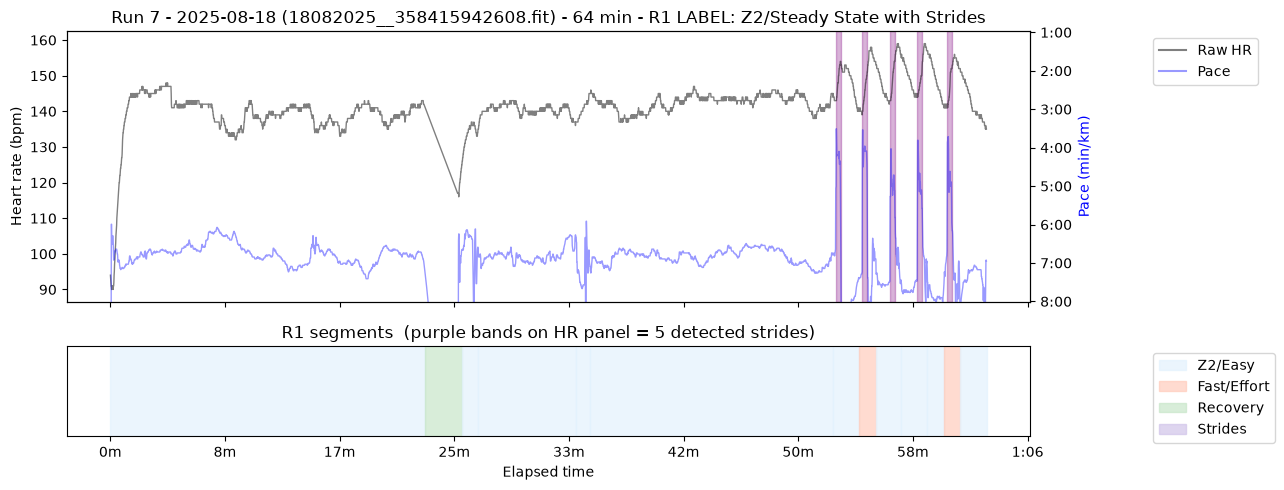

In [9]:
for run_idx, run in enumerate(reviewed):
    plot_run(run, run_idx)